In [1]:
import sys
sys.path.append("..")

%load_ext autoreload
%autoreload 2

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupKFold, RandomizedSearchCV
from sklearn.metrics import make_scorer
from sklearn.ensemble import RandomForestRegressor
from lightgbm import LGBMRegressor
from scipy.stats import randint, uniform, loguniform

from src.metrics import nasa_score
from src.validation import run_cv

In [2]:
df = pd.read_pickle("../data/processed/fd001_basis_c.pkl")
feature_cols_c = [c for c in df.columns if c not in ["unit", "RUL"]]

In [3]:
df.shape

(20631, 100)

In [4]:
len(feature_cols_c)

98

## Tuning: LightGBM und RandomForest

### Ziel
Beide Modelle zeigen mit Default-Parametern eine große Lücke zwischen Train und Val
(Mac mini: LGBM Val 13,24, RF Val 13,46, Train-Werte aus dem Default-Lauf unten).
Frage: Verbessert gezieltes Regularisieren den Val-RMSE, und welches Modell liegt danach vorne?

### Setup
- Basis c (98 Features, geladen aus `fd001_basis_c.pkl`), dieselben 10 GroupKFold-Splits wie in `04`, Mac mini
- `RandomizedSearchCV`, `n_iter`: LGBM 50 / RF 50 (gleicher Selektions-Bias), `random_state = 42`
- `scoring`: RMSE + NASA-Score (`aggregation="mean"` wie in `run_cv`), `refit = "rmse"`
  Begründung: Konsistent mit der Entscheidungsregel vom 22.10. (RMSE ist die Hürde, NASA entscheidet zwischen den Kandidaten). Der NASA-Score bestraft späte Fehler exponentiell und wird dadurch von einzelnen Ausreißer-Triebwerken dominiert. Als Auswahlkriterium für Hyperparameter wäre er zu verrauscht.
- `return_train_score = True` (für die Train/Val-Lücke)
- Parallelisierung: `n_jobs = -1` in der Suche, Modelle mit `n_jobs = 1` (sonst konkurrieren die Prozesse um die Kerne)
- Die Default-Referenz wird in diesem Notebook neu berechnet (gleiche Maschine, gleiche Folds)

### Suchraum LightGBM
| Parameter | Bereich | Verteilung | Default | Warum |
|---|---|---|---|---|
| `num_leaves` | 8–64 | randint | 31 | Weniger Blätter ergeben einfachere Bäume, die weniger Details einzelner Triebwerke abbilden können |
| `min_child_samples` | 10, 20, 40, 80, 160 | Liste (Verdopplung = log-Abstand) | 20 | Größere Blätter mitteln über mehrere Triebwerke statt über aufeinanderfolgende Zyklen eines einzigen |
| `learning_rate` | 0,01–0,2 | loguniform | 0,1 | Kleinere Schritte pro Baum: Das Ensemble lernt vorsichtiger und nimmt weniger Rauschen mit. Log, weil relative Änderungen zählen |
| `n_estimators` | 100–1500 | randint | 100 | Muss zur Lernrate passen: Eine kleine Lernrate braucht mehr Bäume, zu viele Bäume lernen am Ende nur noch die Restfehler (Rauschen) |

Kopplung: `learning_rate` und `n_estimators` hängen zusammen. Gute Kombinationen liegen auf einem diagonalen Streifen.
Prüfung bei der Auswertung: Scatterplot `learning_rate` gegen `n_estimators`, Farbe = RMSE.

### Suchraum RandomForest
| Parameter | Bereich | Verteilung | Default | Warum |
|---|---|---|---|---|
| `max_depth` | None, 8, 12, 16, 20 | Liste | None | Begrenzte Tiefe verhindert, dass Bäume bis zu reinen Blättern wachsen. `None` bleibt drin, damit der Default mitgetestet wird |
| `min_samples_leaf` | 1–50 | randint | 1 | Beim Default 1 kann ein Blatt aus einer einzigen Zeile bestehen, das ist Auswendiglernen. Größere Blätter glätten |
| `max_features` | 0,1–1,0 | uniform | 1,0 | Weniger Features pro Split machen die Bäume unterschiedlicher, dadurch senkt der Mittelwert die Varianz stärker. Nebeneffekt: schneller |
| `n_estimators` | fix 100 | – | 100 | Mehr Bäume senken nur die Varianz bis zu einem Plateau, deshalb fixiert statt getunt |

### Hypothese (vor dem Lauf)
- **H1 LGBM:** Mittlerer RMSE_val > 0,3 besser als Default (13,24) **und** in ≥ 7/10 Folds besser **und** die Train/Val-Lücke schrumpft um ≥ 1,0 (aktuell 6,6)
- **H2 RF:** Mittlerer RMSE_val > 0,3 besser als Default (13,46) **und** in ≥ 7/10 Folds besser **und** die Train/Val-Lücke schrumpft um ≥ 2,0 (aktuell 10,36)
  Die Lücke wird beim RF schwächer gewichtet, weil sein Train-Fehler strukturell klein ist (jeder Baum kennt seine Trainingszeilen fast auswendig).
- **H3:** Nach dem Tuning liegt LGBM weiter vorne, und der Abstand zu RF wächst. Begründung: RF-Defaults gelten als robust, Tuning bringt dort meist wenig. Boosting hat mit `learning_rate`, `n_estimators` und `num_leaves` mehr Hebel. Gegenargument: RF hat die größere Lücke und damit mehr Spielraum.
- **Mechanismus:** Aufeinanderfolgende Zyklen eines Triebwerks sind fast identisch. Kleine Blätter können deshalb einzelne Triebwerke auswendig lernen. Größere Blätter, weniger Komplexität pro Baum und (bei RF) weniger Features pro Split sollten das verhindern: Der Train-RMSE steigt, der Val-RMSE sinkt leicht.
  Schrumpft die Lücke, ohne dass Val besser wird, war Overfitting nicht der Engpass.

### Entscheidungsregel
- H1/H2 gelten als bestätigt, wenn **alle** Teile erfüllt sind.
- Finale Modellwahl (Regel vom 22.10.): Kandidat ist jedes getunte Modell, das seine Hypothese H1/H2 besteht. Bestehen beide, gewinnt das mit dem besseren NASA-Score, weil späte Vorhersagen für die Wartung die gefährliche Richtung sind. Besteht keins, bleibt LGBM mit Default-Parametern.

### Einschränkung
Der beste Such-RMSE ist optimistisch (Selektions-Bias: die beste von `n_iter` Kombinationen, gemessen auf denselben Folds, auf denen sie ausgewählt wurde).
Die ehrliche Zahl liefert erst der Testlauf. Nach dem Testlauf wird nichts mehr getunt.

In [5]:
X = df[feature_cols_c]
y = df["RUL"]
splits = list(GroupKFold(n_splits=10).split(X,y,groups=df["unit"]))

In [6]:
lgbm = run_cv(LGBMRegressor(n_jobs = 1, random_state=42, verbose = -1), X, y, splits)
rf = run_cv(RandomForestRegressor(n_jobs=-1, random_state=42), X, y, splits)

lgbm.to_csv('../data/processed/lgbm_cv.csv', index = False)
rf.to_csv('../data/processed/rf_cv.csv', index = False)

In [7]:
lgbm.drop(columns = "fold").agg("mean")

rmse_train       6.643371
rmse_val        13.241206
nasa_val         3.602103
bias            -0.102583
anteil_spaet     0.461161
max_spaet       54.221874
dtype: float64

In [8]:
rf.drop(columns ="fold").agg("mean")

rmse_train       3.104731
rmse_val        13.459340
nasa_val         3.625276
bias            -0.240784
anteil_spaet     0.392082
max_spaet       53.155000
dtype: float64

In [9]:
RUN_SEARCH = False

nasa_scorer = make_scorer(nasa_score, greater_is_better=False, aggregation = "mean")
scoring = {"rmse": "neg_root_mean_squared_error", "nasa": nasa_scorer}

In [10]:
param_lgbm = {
    "num_leaves": randint(8,65),
    "min_child_samples": [10,20,40,80,160],
    "learning_rate": loguniform(0.01, 0.2),
    "n_estimators": randint(100,1501)
}

param_rf = {
    "max_depth": [None, 8, 12, 16, 20],
    "min_samples_leaf": randint(1, 51),
    "max_features": uniform(0.1,0.9)
}

In [11]:
%%time
if RUN_SEARCH:

    search_lgbm = RandomizedSearchCV(
                    estimator=LGBMRegressor(n_jobs=1, random_state=42, verbose=-1),
                    param_distributions = param_lgbm,
                    n_iter =50,
                    scoring=scoring,
                    refit="rmse",
                    cv=splits,
                    n_jobs=-1,
                    return_train_score= True,
                    random_state=42,
                    )
    search_lgbm.fit(X,y);
    pd.to_pickle(search_lgbm, "../data/processed/search_lgbm.pkl")

search_lgbm = pd.read_pickle("../data/processed/search_lgbm.pkl")    

CPU times: user 10.3 ms, sys: 2.04 ms, total: 12.4 ms
Wall time: 14.8 ms


In [12]:
%%time
if RUN_SEARCH:

    search_rf = RandomizedSearchCV(
                    estimator=RandomForestRegressor(n_jobs=1, random_state=42, n_estimators=100),
                    param_distributions = param_rf,
                    n_iter =50,
                    scoring=scoring,
                    refit="rmse",
                    cv=splits,
                    n_jobs=-1,
                    return_train_score= True,
                    random_state=42,
                    )
    search_rf.fit(X,y);
    pd.to_pickle(search_rf, "../data/processed/search_rf.pkl")

search_rf = pd.read_pickle("../data/processed/search_rf.pkl") 

CPU times: user 2.98 ms, sys: 4.48 ms, total: 7.46 ms
Wall time: 12.4 ms


In [13]:
res_lgbm = pd.DataFrame(search_lgbm.cv_results_)
display(res_lgbm[["mean_fit_time", "mean_test_rmse", "mean_train_rmse", "split0_test_rmse"]])

res_rf = pd.DataFrame(search_rf.cv_results_)
display(res_rf[["mean_fit_time", "mean_test_rmse", "mean_train_rmse", "split0_test_rmse"]])

,mean_fit_time,mean_test_rmse,mean_train_rmse,split0_test_rmse
0,22.637610,-13.330618,-1.768921,-13.477388
1,2.660859,-13.415681,-5.367438,-13.238270
2,4.333162,-13.583132,-9.558271,-14.147524
3,8.451525,-13.440845,-5.012062,-13.493755
4,13.004379,-13.408943,-1.013739,-13.559384
5,2.396263,-13.059744,-5.577716,-13.430416
6,19.920856,-13.007576,-4.343658,-13.457291
7,10.544703,-13.036234,-7.248175,-13.359538
8,23.760721,-13.147767,-0.760743,-13.570305
9,9.113793,-12.974111,-7.296691,-13.357126


,mean_fit_time,mean_test_rmse,mean_train_rmse,split0_test_rmse
0,64.652955,-13.917436,-10.398193,-14.627747
1,47.798550,-13.277401,-8.294585,-13.822684
2,32.015367,-13.487186,-10.203500,-14.171933
3,8.655440,-13.294866,-7.610741,-14.222166
4,79.291724,-13.355317,-4.432510,-13.960733
5,19.244952,-13.138348,-7.670024,-13.978490
6,29.345476,-13.911685,-11.734206,-14.669017
7,23.513685,-13.486191,-10.473375,-14.309679
8,71.977902,-13.492221,-7.654240,-14.000609
9,31.919043,-13.151098,-6.943479,-13.834297


In [14]:
res_lgbm.shape

(50, 59)

In [15]:
res_rf.shape

(50, 58)

In [16]:
res_rf.isna().sum()

mean_fit_time             0
std_fit_time              0
mean_score_time           0
std_score_time            0
param_max_depth           9
param_max_features        0
param_min_samples_leaf    0
params                    0
split0_test_rmse          0
split1_test_rmse          0
split2_test_rmse          0
split3_test_rmse          0
split4_test_rmse          0
split5_test_rmse          0
split6_test_rmse          0
split7_test_rmse          0
split8_test_rmse          0
split9_test_rmse          0
mean_test_rmse            0
std_test_rmse             0
rank_test_rmse            0
split0_train_rmse         0
split1_train_rmse         0
split2_train_rmse         0
split3_train_rmse         0
split4_train_rmse         0
split5_train_rmse         0
split6_train_rmse         0
split7_train_rmse         0
split8_train_rmse         0
split9_train_rmse         0
mean_train_rmse           0
std_train_rmse            0
split0_test_nasa          0
split1_test_nasa          0
split2_test_nasa    

In [17]:
res_lgbm.isna().sum().sum()

np.int64(0)

In [18]:
res_rf[res_rf["rank_test_rmse"]==1][["mean_test_rmse", "mean_train_rmse", "mean_test_nasa", "std_test_rmse"]]

,mean_test_rmse,mean_train_rmse,mean_test_nasa,std_test_rmse
14,-13.089256,-6.22158,-3.355807,1.879868


In [19]:
res_lgbm[res_lgbm["rank_test_rmse"]==1][["mean_test_rmse", "mean_train_rmse", "mean_test_nasa", "std_test_rmse"]]

,mean_test_rmse,mean_train_rmse,mean_test_nasa,std_test_rmse
9,-12.974111,-7.296691,-3.317803,1.666638


In [20]:
split_cols = [f"split{i}_test_rmse" for i in range(10)]
best_lgbm = res_lgbm[res_lgbm["rank_test_rmse"]==1]

In [21]:
lgbm_tuned_folds = -(best_lgbm[split_cols].iloc[0]).to_numpy()


In [22]:
lgbm_default_folds = lgbm["rmse_val"].to_numpy()


In [23]:
(lgbm_tuned_folds<lgbm_default_folds).sum()

np.int64(10)

In [24]:
best_rf = res_rf[res_rf["rank_test_rmse"]==1]
rf_tuned_folds = -(best_rf[split_cols].iloc[0]).to_numpy()
rf_default_folds = rf["rmse_val"].to_numpy()

In [25]:
(rf_tuned_folds<rf_default_folds).sum()

np.int64(10)

In [26]:
res_lgbm.columns

Index(['mean_fit_time', 'std_fit_time', 'mean_score_time', 'std_score_time',
       'param_learning_rate', 'param_min_child_samples', 'param_n_estimators',
       'param_num_leaves', 'params', 'split0_test_rmse', 'split1_test_rmse',
       'split2_test_rmse', 'split3_test_rmse', 'split4_test_rmse',
       'split5_test_rmse', 'split6_test_rmse', 'split7_test_rmse',
       'split8_test_rmse', 'split9_test_rmse', 'mean_test_rmse',
       'std_test_rmse', 'rank_test_rmse', 'split0_train_rmse',
       'split1_train_rmse', 'split2_train_rmse', 'split3_train_rmse',
       'split4_train_rmse', 'split5_train_rmse', 'split6_train_rmse',
       'split7_train_rmse', 'split8_train_rmse', 'split9_train_rmse',
       'mean_train_rmse', 'std_train_rmse', 'split0_test_nasa',
       'split1_test_nasa', 'split2_test_nasa', 'split3_test_nasa',
       'split4_test_nasa', 'split5_test_nasa', 'split6_test_nasa',
       'split7_test_nasa', 'split8_test_nasa', 'split9_test_nasa',
       'mean_test_nasa', 'std_

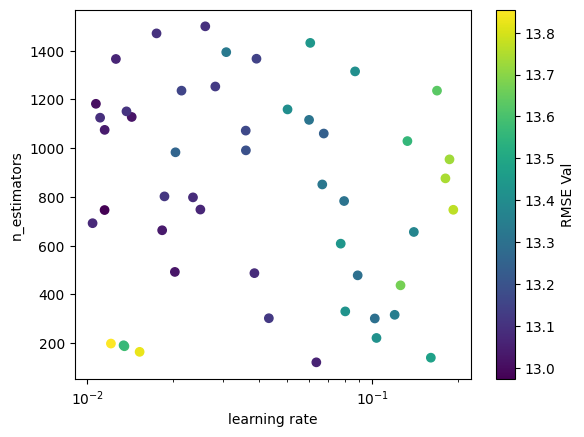

In [27]:
rmse_werte = res_lgbm["mean_test_rmse"]*(-1)
x_plot = res_lgbm["param_learning_rate"]
y_plot = res_lgbm["param_n_estimators"]

plt.scatter(x_plot,y_plot, c=rmse_werte)
plt.xscale("log")
plt.colorbar(label = "RMSE Val")
plt.xlabel("learning rate")
plt.ylabel("n_estimators")
plt.show()

In [28]:
res_rf.columns

Index(['mean_fit_time', 'std_fit_time', 'mean_score_time', 'std_score_time',
       'param_max_depth', 'param_max_features', 'param_min_samples_leaf',
       'params', 'split0_test_rmse', 'split1_test_rmse', 'split2_test_rmse',
       'split3_test_rmse', 'split4_test_rmse', 'split5_test_rmse',
       'split6_test_rmse', 'split7_test_rmse', 'split8_test_rmse',
       'split9_test_rmse', 'mean_test_rmse', 'std_test_rmse', 'rank_test_rmse',
       'split0_train_rmse', 'split1_train_rmse', 'split2_train_rmse',
       'split3_train_rmse', 'split4_train_rmse', 'split5_train_rmse',
       'split6_train_rmse', 'split7_train_rmse', 'split8_train_rmse',
       'split9_train_rmse', 'mean_train_rmse', 'std_train_rmse',
       'split0_test_nasa', 'split1_test_nasa', 'split2_test_nasa',
       'split3_test_nasa', 'split4_test_nasa', 'split5_test_nasa',
       'split6_test_nasa', 'split7_test_nasa', 'split8_test_nasa',
       'split9_test_nasa', 'mean_test_nasa', 'std_test_nasa', 'rank_test_nasa',
  

In [29]:
top5_lgbm = res_lgbm.sort_values("rank_test_rmse").head(5)[["param_learning_rate", "param_min_child_samples", "param_n_estimators", "param_num_leaves", "mean_test_rmse", "std_test_rmse"]]
top5_rf = res_rf.sort_values("rank_test_rmse").head(5)[["param_max_depth", "param_min_samples_leaf", "param_max_features", "mean_test_rmse", "std_test_rmse"]]

display(top5_lgbm)
display(top5_rf)

,param_learning_rate,param_min_child_samples,param_n_estimators,param_num_leaves,mean_test_rmse,std_test_rmse
9,0.011493,40,746,28,-12.974111,1.666638
6,0.010715,40,1182,49,-13.007576,1.774671
28,0.014309,40,1128,33,-13.022070,1.731997
29,0.020278,40,492,22,-13.025236,1.603314
31,0.018300,10,663,39,-13.033662,1.735207


,param_max_depth,param_min_samples_leaf,param_max_features,mean_test_rmse,std_test_rmse
14,16,7,0.316923,-13.089256,1.879868
5,16,12,0.265064,-13.138348,1.916642
11,None,4,0.158546,-13.144742,1.958543
9,12,3,0.444216,-13.151098,1.889724
28,12,8,0.278958,-13.166805,1.925969


In [30]:
(lgbm_tuned_folds<rf_tuned_folds).sum()

np.int64(4)

## Auswertung Tuning: Hypothesen H1–H3

| | Bedingung | Default | Getunt | erfüllt? |
|---|---|---|---|---|
| **H1** LGBM | RMSE_val mehr als 0,3 besser | 13,24 | 12,97 | nein |
| | ≥ 7/10 Folds besser | – | 10/10 | ja |
| | Lücke Train/Val < 5,60 | 6,6 | 5,68 | nein |
| **H2** RF | RMSE_val mehr als 0,3 besser | 13,46 | 13,09 | ja |
| | ≥ 7/10 Folds besser | – | 10/10 | ja |
| | Lücke Train/Val < 8,35 | 10,36 | 6,87 | ja |
| **H3** | LGBM vorne | ja | ja | ja |
| | Abstand LGBM zu RF wächst | 0,22 | 0,12 | nein |

**Ergebnis:** H1 nicht erfüllt · H2 erfüllt · H3. nicht erfüllt

### Gegenprobe NASA-Score

| | Default | Getunt | Veränderung |
|---|---|---|---|
| LGBM | 3,60 | 3,31 | -0,29 |
| RF | 3,62 | 3,35 | -0,27 |

→ Der NASA-Score verbessert sich bei beiden Modellen in dieselbe Richtung wie die RMSE → kein Widerspruch zwischen den Metriken.

### Lücke beim RF: Val besser oder Train schlechter?

| | Default | Getunt | Veränderung |
|---|---|---|---|
| RMSE Train | 3,10 | 6,22 | +3,12 |
| RMSE Val | 13,46 | 13,09 | -0,37 |
| Lücke | 10,36 | 6,87 | - |

→ Vor allem Train schlechter: Von 3,49 weniger Lücke kommen 3,12 aus dem höheren Train-Fehler, nur 0,37 aus besserem Val. Eine kleinere Lücke allein ist kein Qualitätsbeweis, Overfitting war beim RF nur zum kleinen Teil der Engpass.

### Warnzeichen

- **Beste Parameter am Rand des Suchraums:** LGBM `learning_rate` = 0,0115 liegt nahe der Untergrenze 0,01. Die gute Region reicht aber bei passender Baumanzahl von 0,01 bis ca. 0,04 (diagonaler Streifen im Scatter) → eher Plateau als ein Optimum jenseits der Grenze · `n_estimators` (746) liegt nicht am Rand · RF: alle drei Bestwerte im Inneren des Suchraums
- **Plateau oder Einzelkombination:** Plateau bei beiden Modellen. Rang 1 → 5 liegen nur 0,06 (LGBM) bzw. 0,08 (RF) auseinander, ca. 4 % der Fold-Std (≈ 1,7 / 1,9) · Die Top 5 liegen in derselben Region: LGBM `learning_rate` 0,011–0,020, `min_child_samples` = 40 bei 4/5 · RF `max_features` 0,16–0,44 statt Default 1,0 → stärkstes Signal der Suche: Feature-Subsampling macht die Bäume unterschiedlicher
- **Selektions-Bias:** Die beste von 50 Ziehungen auf denselben 10 Folds ist optimistisch · Verbesserung LGBM 0,27 konsistent (10/10 Folds), aber klein · Prüfung auf frischen Folds: siehe unten

### Entscheidung finales Modell

- **Regel vom 22.10.:** Die Referenz wird nur abgelöst bei mittlerer RMSE_val ≥ 0,5 besser **und** ≥ 8/10 Folds besser **und** NASA nicht schlechter · schaffen es mehrere → bester NASA-Score · schafft es keins → Referenz bleibt
- **Gewählt:** LightGBM mit Default-Parametern (Referenz seit 22.10.)
- **Begründung:** Kein getuntes Modell erfüllt die Regel. LGBM getunt ist nur 0,27 besser (10/10 Folds, NASA 3,60 → 3,32), RF getunt nur 0,15 besser als LGBM Default · H1 verfehlt · Die Verbesserung ist mit 0,27 Zyklen (≈ 2 %) praktisch nicht relevant, kostet aber 746 statt 100 Bäume · Die Schwelle wird nicht nachträglich angepasst

**Prüfung ob Unterschied LGBM_tuned im Vergleich zu LGBM_default nur Selektions-Bias ist oder einen echten Unterschied macht**

In [31]:
splits_neu = list(GroupKFold(n_splits=10, shuffle=True, random_state=7).split(X,y,groups=df["unit"]))

In [32]:
for fold, (train_idx, val_idx) in enumerate(splits_neu):
    train_units = set(df["unit"].iloc[train_idx])
    val_units = set(df["unit"].iloc[val_idx])
    overlap = train_units & val_units
    print(f"Fold {fold}: {len(val_units)} Triebwerke, {len(val_idx)} Zeilen, Überschneidung {len(overlap)}")

Fold 0: 10 Triebwerke, 2114 Zeilen, Überschneidung 0
Fold 1: 10 Triebwerke, 2063 Zeilen, Überschneidung 0
Fold 2: 10 Triebwerke, 2087 Zeilen, Überschneidung 0
Fold 3: 10 Triebwerke, 1958 Zeilen, Überschneidung 0
Fold 4: 10 Triebwerke, 2041 Zeilen, Überschneidung 0
Fold 5: 10 Triebwerke, 2141 Zeilen, Überschneidung 0
Fold 6: 10 Triebwerke, 1893 Zeilen, Überschneidung 0
Fold 7: 10 Triebwerke, 2218 Zeilen, Überschneidung 0
Fold 8: 10 Triebwerke, 1919 Zeilen, Überschneidung 0
Fold 9: 10 Triebwerke, 2197 Zeilen, Überschneidung 0


In [33]:
val_alt = set(df["unit"].iloc[splits[0][1]])
val_neu = set(df["unit"].iloc[splits_neu[0][1]])

val_alt == val_neu

False

**Hypothese:**
Getunt ist auch auf frischen Folds um > 0,35 besser in ≥ 8/10 Folds → Verbesserung echt, aber unter der Relevanzschwelle. Sonst: Selektions-Bias.

#### Getuntes Modell aus `cv_results_`
Exakte Parameter aus der Rang-1-Zeile der gespeicherten Suchergebnisse – nichts abgetippt, läuft auch mit `RUN_SEARCH = False`.

In [34]:
lgbm_tuned_params = {}

zeile = res_lgbm[res_lgbm["rank_test_rmse"]==1].iloc[0]

for name in zeile.index:
    if name.startswith("param_"):
        param_name = name.replace("param_", "")
        lgbm_tuned_params[param_name] = zeile[name]

In [35]:
print(lgbm_tuned_params)

{'learning_rate': np.float64(0.011492999300221412), 'min_child_samples': np.int64(40), 'n_estimators': np.int64(746), 'num_leaves': np.int64(28)}


In [36]:
print(type(lgbm_tuned_params["num_leaves"]))

<class 'numpy.int64'>


In [37]:
lgbm_tuned = LGBMRegressor(**lgbm_tuned_params, verbose=-1, n_jobs = 1, random_state =42)

In [38]:
lgbm_default_neu = run_cv(LGBMRegressor(verbose = -1, n_jobs = 1, random_state=42),X,y,splits_neu)
lgbm_tuned_neu = run_cv(lgbm_tuned, X,y, splits_neu)

print(lgbm_default_neu.agg("mean"))
print(lgbm_tuned_neu.agg("mean"))

fold             4.500000
rmse_train       6.643193
rmse_val        13.331277
nasa_val         3.544747
bias            -0.094670
anteil_spaet     0.460762
max_spaet       51.958050
dtype: float64
fold             4.500000
rmse_train       7.293637
rmse_val        13.172883
nasa_val         3.425671
bias            -0.068003
anteil_spaet     0.462289
max_spaet       51.960904
dtype: float64


In [39]:
(lgbm_tuned_neu["rmse_val"]<lgbm_default_neu["rmse_val"]).sum()

np.int64(10)

### Prüfung des Selektions-Bias auf frischen Folds – Ergebnis

**Setup:** Triebwerke neu auf 10 Folds verteilt (`GroupKFold(shuffle=True, random_state=7)`), keine neue Suche – nur LGBM Default und LGBM mit den getunten Parametern als feste Modelle · Kontrollen: keine Triebwerks-Überschneidung zwischen Train und Val ✓, Val-Triebwerke Fold 0 ≠ alter Fold 0 ✓

| | Original-Folds | Frische Folds |
|---|---|---|
| RMSE_val Default | 13,24 | 13,33 |
| RMSE_val getunt | 12,97 | 13,17 |
| **Vorsprung getunt** | **0,27** | **0,16** |
| Folds getunt besser | 10/10 | 10/10 |
| NASA Default → getunt | 3,60 → 3,32 | 3,54 → 3,43 |

**Hypothese → widerlegt:** 0,16 statt > 0,35 (Folds 10/10 ✓). Nach der vorab festgelegten Regel ist die Verbesserung damit nicht als echt nachgewiesen.

**Beschreibend:** Die Richtung bleibt in allen Folds konsistent, ca. 0,11 (≈ 40 %) des Vorsprungs verschwinden aber mit der neuen Fold-Zuordnung. Allein die neue Zuordnung verschiebt auch den Default um ca. 0,1 → Unterschiede in dieser Größenordnung sind kaum von Split-Rauschen zu trennen.

**Lernpunkt:** Die Schwelle 0,35 lag über dem ursprünglichen Vorsprung (0,27) und wäre nur bei einem *wachsenden* Vorsprung erfüllbar gewesen. Schwellen für Nachprüfungen künftig relativ zum Ausgangswert setzen.

**Konsequenz:** Die Entscheidung bleibt **LightGBM Default**. Die Schwelle wird nicht nachträglich angepasst.